In [20]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import elli

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Permittivity changes estimation')
from Permittivity_change_func import *
import Permittivity_change_func
importlib.reload(Permittivity_change_func)
from Permittivity_change_func  import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Calculation of permittivity change with acoustic modes

Here, we focus on the contribution to $\sigma_{ext}(\lambda)$ :
$$\Delta \sigma_{ext}(\lambda) = \frac{\partial \sigma_{ext}}{\partial \varepsilon_1} \Delta \varepsilon_1 + \frac{\partial \sigma_{ext}}{\partial \varepsilon_2} \Delta \varepsilon_2$$

And then : 
$$ \Delta \varepsilon_1(\lambda) = \left( a^D(\lambda) + a^{ib}(\lambda) \right) \left( \frac{dV}{V} \right)$$
$$ \Delta \varepsilon_2(\lambda) = \left( b^D(\lambda) + b^{ib}(\lambda) \right) \left( \frac{dV}{V} \right)$$

In [21]:
Data_to_save = {}

## Calculate the Drude contribution

In [22]:
#Table_choice = "JaC"
Table_choice = 'JaC'

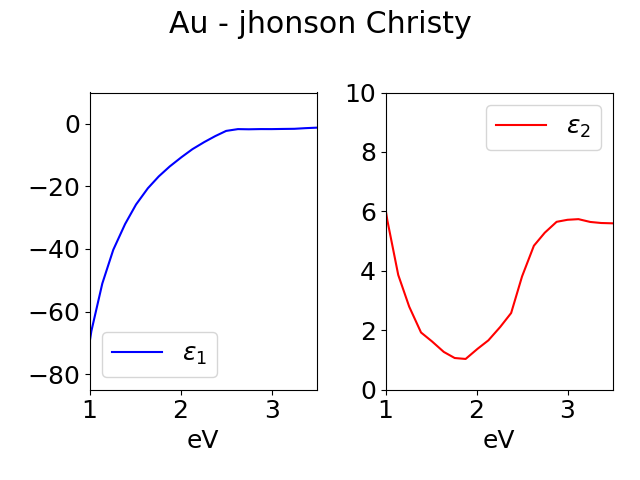

In [23]:
# Get the Jhonson and Christy permittivity.
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\Data_refractive_index'

if Table_choice == 'Olmon' :
    fname = 'Au - Olmon monocrystal.csv'
if Table_choice == 'JaC' :
    fname = 'Au - jhonson Christy.csv'



data = get_permittivity_tabulated_data(dir_root, fname)


fig, ax = plt.subplots(ncols=2)
ax[0].plot(data['eV'], data['eps_1'], label =r'$\varepsilon_1$', color='blue')
ax[0].set_xlabel('eV')

ax[0].legend()
ax[0].set_xlim((1, 3.5))
ax[0].set_ylim((-85, 10))
plt.tight_layout()


ax[1].plot(data['eV'], data['eps_2'], label =r'$\varepsilon_2$', color='red')
ax[1].set_xlabel('eV')

ax[1].legend()
ax[1].set_xlim((1, 3.5))
ax[1].set_ylim((0, 10))
plt.suptitle(fname[:-4])
plt.tight_layout()


## Calculate the Drude contribution in permittivity

For the Drude contribution, we ony take into account the change of condution electron density and its repercussion on the plasmon resonance (check my obsidian notes for more details) :

$$d\varepsilon^D_1 (\lambda) = (1-\varepsilon_1^D(\lambda)) \left( \frac{dV}{V} \right)$$
$$d\varepsilon^D_2 (\lambda) = -\varepsilon_2^D(\lambda) \left( \frac{dV}{V} \right)$$

Leading to :
$$a^D(\lambda) = 1 - \varepsilon_1^D(\lambda)$$
$$b^D(\lambda) = - \varepsilon_2^D(\lambda)$$

In [24]:


if Table_choice == 'Olmon' :
    #Gold values from Olmon 2012, for monocrystal
    w_p = 8.1 * sc.constants.e / sc.constants.hbar 
    gamma_0 = (1/14)*1e15

    
if Table_choice == 'JaC' :
    #Gold values from Romain PhD manuscript
    w_p = 9.01 * sc.constants.e / sc.constants.hbar 
    gamma_0 = 70*1e-3 * sc.constants.e / sc.constants.hbar



def eps_1_drude(w, gamma=gamma_0, w_p=w_p) :
    return(1 - (w_p**2)/(w**2+gamma**2))

def eps_2_drude(w, gamma=gamma_0, w_p=w_p) :
    return((gamma*w_p**2)/(w*(w**2 + gamma**2)))


def a_drude(w) :
    return (1- eps_1_drude(w))

def b_drude(w) :
    return(-eps_2_drude(w))

# in rad/s
def a_drude_rad(w) :
    return (1- eps_1_drude(w))
def b_drude_rad(w) :
    return(-eps_2_drude(w))

# in eV
def a_drude_ernergy(energy) :
    return (1- eps_1_drude(energy* sc.constants.e / sc.constants.hbar  ))
def b_drude_ernergy(energy) :
    return(-eps_2_drude(energy * sc.constants.e / sc.constants.hbar ))

# in meters
def a_drude_wavelength(lda) :
    return (1- eps_1_drude(2*np.pi*sc.constants.c /lda))
def b_drude_wavelength(lda) :
    return(-eps_2_drude(2*np.pi*sc.constants.c /lda))

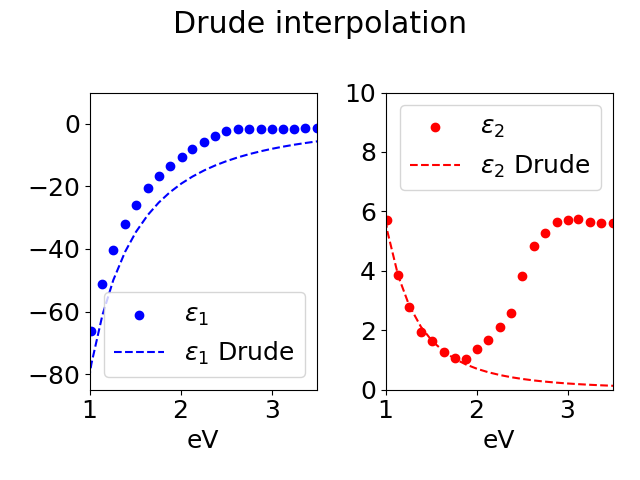

In [25]:
fig, ax = plt.subplots(ncols=2)
ax[0].scatter(data['eV'], data['eps_1'], label =r'$\varepsilon_1$', color='blue')
ax[0].set_xlabel('eV')
ax[0].plot(data['eV'], eps_1_drude(2*np.pi*sc.constants.c/data['lambda']*1e9), label =r'$\varepsilon_1$ Drude', linestyle='--', color='blue')

ax[0].legend()
ax[0].set_xlim((1, 3.5))
ax[0].set_ylim((-85, 10))



ax[1].scatter(data['eV'], data['eps_2'], label =r'$\varepsilon_2$', color='red')

ax[1].plot(data['eV'], eps_2_drude(2*np.pi*sc.constants.c/data['lambda']*1e9), label =r'$\varepsilon_2$ Drude', linestyle='--', color='red')

ax[1].set_xlabel('eV')

ax[1].legend()
ax[1].set_xlim((1, 3.5))
ax[1].set_ylim((0, 10))
plt.suptitle('Drude interpolation')
plt.tight_layout()


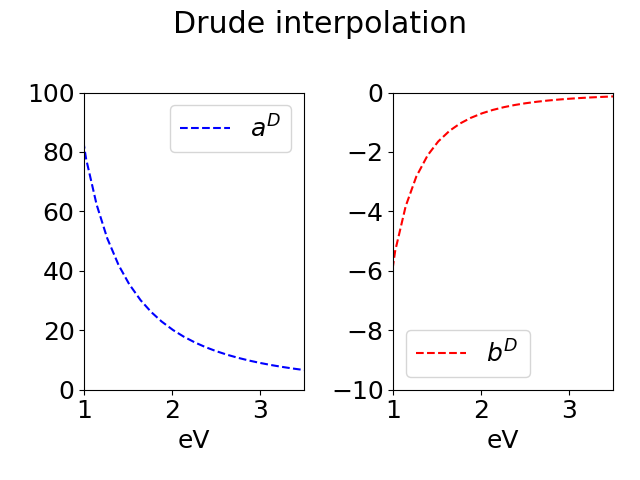

In [26]:
fig, ax = plt.subplots(ncols=2)

ax[0].set_xlabel('eV')
ax[0].plot(data['eV'], a_drude(2*np.pi*sc.constants.c/data['lambda']*1e9), label =r'$a^D$', linestyle='--', color='blue')

ax[0].legend()
ax[0].set_xlim((1, 3.5))
ax[0].set_ylim((0, 100))


ax[1].plot(data['eV'], b_drude(2*np.pi*sc.constants.c/data['lambda']*1e9), label =r'$ b^D$ ', linestyle='--', color='red')

ax[1].set_xlabel('eV')

ax[1].legend()
ax[1].set_xlim((1, 3.5))
ax[1].set_ylim((-10, 0))
plt.suptitle('Drude interpolation')
plt.tight_layout()



Data_to_save['lambda'] = data['lambda']
Data_to_save['eV'] = data['eV']
Data_to_save['a_D'] = a_drude(2*np.pi*sc.constants.c/data['lambda']*1e9)
Data_to_save['b_D'] = b_drude(2*np.pi*sc.constants.c/data['lambda']*1e9)

## Interband contributions

First, we compute the interband part of permittivity :
$$ \varepsilon(\lambda) = \varepsilon^D(\lambda) + \varepsilon^{ib}(\lambda) - 1$$
$$\varepsilon^{ib}(\lambda) = 1 + (\varepsilon(\lambda) - \varepsilon^D(\lambda))$$

In [27]:
data['eps_1_ib'] = 1 + data['eps_1'] - eps_1_drude(2*np.pi*sc.constants.c/data['lambda']*1e9)
data['eps_2_ib'] = data['eps_2'] - eps_2_drude(2*np.pi*sc.constants.c/data['lambda']*1e9)

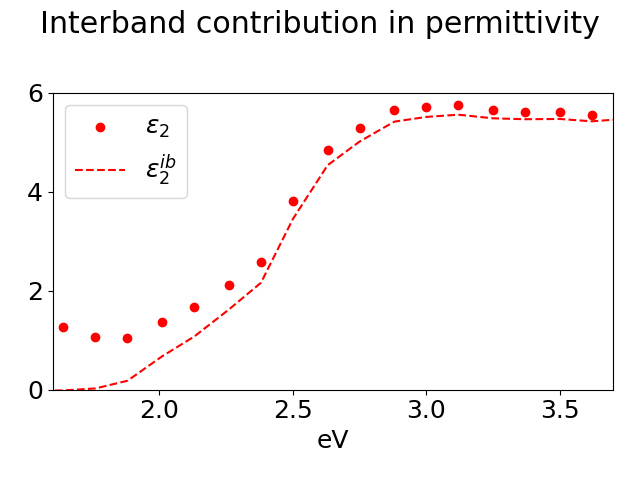

In [28]:
fig, ax = plt.subplots()

ax.scatter(data['eV'], data['eps_2'], label =r'$\varepsilon_2$', color='red')

ax.plot(data['eV'], data['eps_2_ib'], label =r'$\varepsilon_2^{ib}$', linestyle='--', color='red')

ax.set_xlabel('eV')

ax.legend()
ax.set_xlim((1.6, 3.7))
ax.set_ylim((0, 6))
plt.suptitle('Interband contribution in permittivity')
plt.tight_layout()

$$\Delta \varepsilon_2^{ib} = -\sum_m \frac{\partial \varepsilon^{ib}_{2, m}}{\partial \lambda} \Delta \lambda_{ib,m}$$

$$\Delta \lambda_{ib,m} = \frac{\partial \lambda_{ib,m}}{\partial V} \Delta V = \left( \frac{\partial \lambda_{ib,m}}{\partial T
} \cdot \frac{\partial T}{\partial V
}\right) \Delta V = \frac{\partial \lambda_{ib,m}}{\partial T} \frac{dV}{3\alpha V}$$

In [29]:
alpha = 1.42e-5 #in K-1

dwp_dT_1 = -1.7e-4 # for the d->p (L) transition, in eV/K
dwp_dT_2 = -3.2e-4 # for the d->p (X) transntion, in eV/K

print(-1.7e-4/(3*alpha))

-3.990610328638498


In [30]:
# Get the Jhonson and Christy permittivity.
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Acoustic model - data'
fname_eps1 = 'interband_permittivity_change_stoll_2014_eps1.csv'
fname_eps2 = 'interband_permittivity_change_stoll_2014_eps2.csv'

Data_interband ={}
Data_interband['eps1'] ={}
Data_interband['eps2'] ={}

os.chdir(dir_root)
f = pd.read_csv(fname_eps1)
Data_interband['eps1']['lambda'] = (f['lambda'].__array__())
Data_interband['eps1']['eV'] = 1240/Data_interband['eps1']['lambda']
Data_interband['eps1']['Delta_eps1'] = f['Delta eps1 ib (1K)'].__array__()
Data_interband['eps1']['a_ib'] = Data_interband['eps1']['Delta_eps1']/(3*alpha)


os.chdir(dir_root)
f2 = pd.read_csv(fname_eps2)
Data_interband['eps2']['lambda'] = (f2['lambda'].__array__())
Data_interband['eps2']['eV'] = 1240/Data_interband['eps2']['lambda']
Data_interband['eps2']['Delta_eps2'] = f2['Delta eps2 ib (1K)'].__array__()
Data_interband['eps2']['b_ib'] = Data_interband['eps2']['Delta_eps2']/(3*alpha)

KeyError: 'lambda'

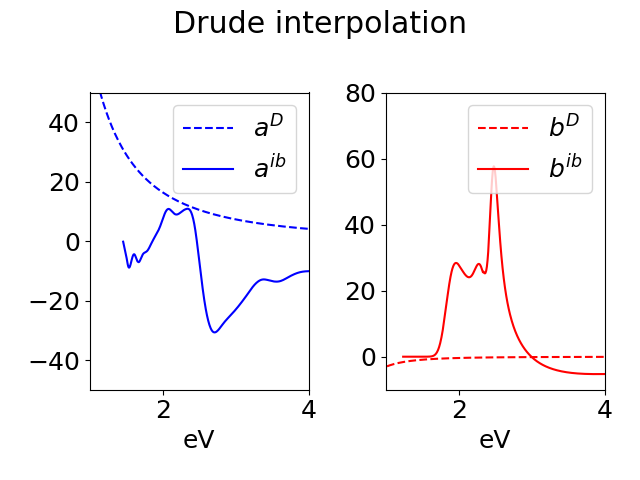

In [ ]:
fig, ax = plt.subplots(ncols=2)

ax[0].set_xlabel('eV')
ax[0].plot(data['eV'], a_drude(2*np.pi*sc.constants.c/data['lambda']*1e9), label =r'$a^D$', linestyle='--', color='blue')
ax[0].plot(Data_interband['eps1']['eV'], Data_interband['eps1']['a_ib'], label=r'$a^{ib}$', color='blue' )
ax[0].legend()
ax[0].set_xlim((1, 4))
ax[0].set_ylim((-50, 50))


ax[1].plot(data['eV'], b_drude(2*np.pi*sc.constants.c/data['lambda']*1e9), label =r'$ b^D$ ', linestyle='--', color='red')
ax[1].plot(Data_interband['eps2']['eV'], Data_interband['eps2']['b_ib'], label=r'$b^{ib}$', color='red' )
ax[1].set_xlabel('eV')

ax[1].legend()
ax[1].set_xlim((1, 4))
ax[1].set_ylim((-10, 80))
plt.suptitle('Drude interpolation')
plt.tight_layout()



Data_to_save['lambda'] = data['lambda']
Data_to_save['eV'] = data['eV']
Data_to_save['a_D'] = a_drude(2*np.pi*sc.constants.c/data['lambda']*1e9)
Data_to_save['b_D'] = b_drude(2*np.pi*sc.constants.c/data['lambda']*1e9)

In [ ]:
Permittivity_change_interp = {}

Permittivity_change_interp['a_ib'] = sc.interpolate.interp1d(Data_interband['eps1']['lambda'], Data_interband['eps1']['a_ib'], fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_change_interp['b_ib'] = sc.interpolate.interp1d(Data_interband['eps2']['lambda'], Data_interband['eps2']['b_ib'], fill_value=0, kind='quadratic', bounds_error=False)

Permittivity_change_interp['a_D'] = sc.interpolate.interp1d(Data_to_save['lambda'], Data_to_save['a_D'], fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_change_interp['b_D'] = sc.interpolate.interp1d(Data_to_save['lambda'], Data_to_save['b_D'], fill_value=0, kind='quadratic', bounds_error=False)

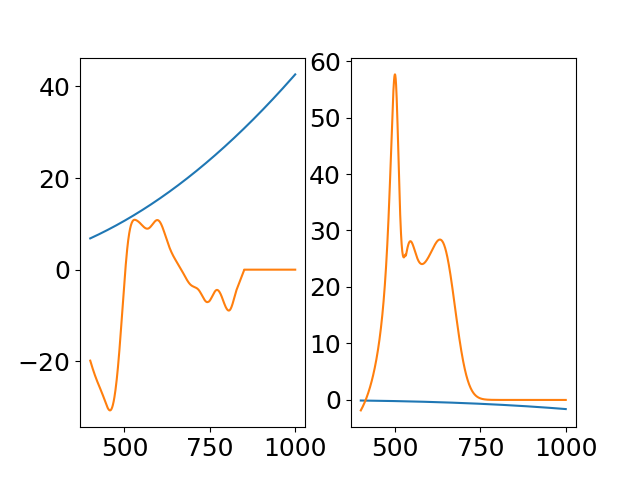

In [ ]:
Lambda = np.linspace(400, 1000, 1000)

fig, ax = plt.subplots(ncols = 2)


ax[0].plot(Lambda, Permittivity_change_interp['a_D'](Lambda), label=r'$a^D$')
ax[0].plot(Lambda, Permittivity_change_interp['a_ib'](Lambda), label=r'$a^{ib}$')


ax[1].plot(Lambda, Permittivity_change_interp['b_D'](Lambda), label=r'$b^D$')
ax[1].plot(Lambda, Permittivity_change_interp['b_ib'](Lambda), label=r'$b^{ib}$')

## Get Plasmonic derivatives

In [ ]:
ND_names = ['Sapphire 2,3 - NDd zone 3', 'Silice thick 4,5 - D1 zone1', 'Membrane 3,5 - ND3,5-5']

global_dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study'

All_data = {}

for key in ND_names :
    print(key)
    All_data[key] = {}
    dir_plasmonic = '\\'.join((global_dir_root, key, 'Optical sensitivity calculation'))
    All_data[key]['plasmonic_derivative'] = get_plasmonic_derivatives(dir_plasmonic, 'plasmonic_derivatives.csv')


Plasmon_derivatives = {}

for key in ND_names :
    Plasmon_derivatives[key] = {}

    Plasmon_derivatives[key]['ds_deps1'] = sc.interpolate.interp1d(All_data[key]['plasmonic_derivative']['lambda'], All_data[key]['plasmonic_derivative']['dsigma/deps1'], fill_value=0, kind='quadratic', bounds_error=False)
    Plasmon_derivatives[key]['ds_deps2'] = sc.interpolate.interp1d(All_data[key]['plasmonic_derivative']['lambda'], All_data[key]['plasmonic_derivative']['dsigma/deps2'], fill_value=0, kind='quadratic', bounds_error=False)




Sapphire 2,3 - NDd zone 3
Silice thick 4,5 - D1 zone1
Membrane 3,5 - ND3,5-5


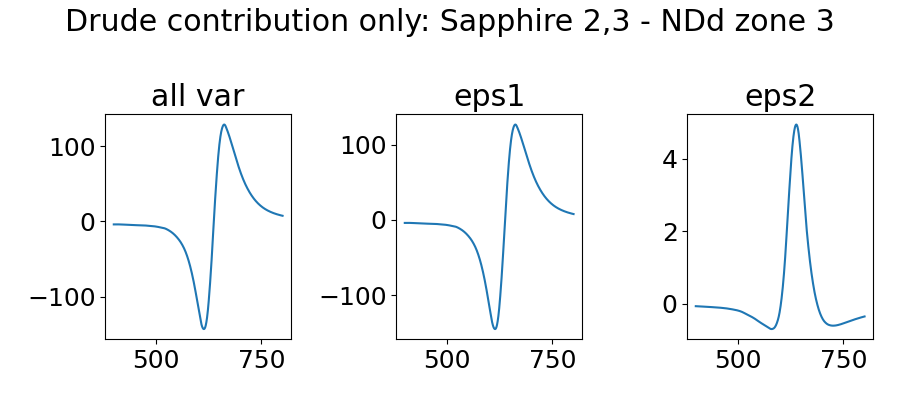

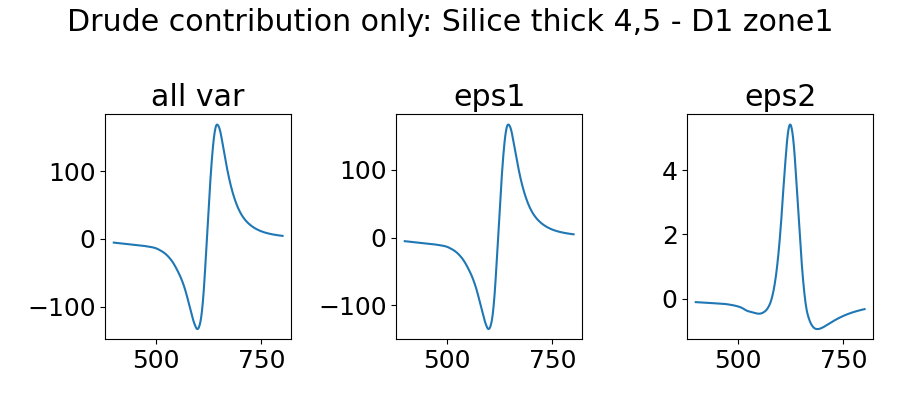

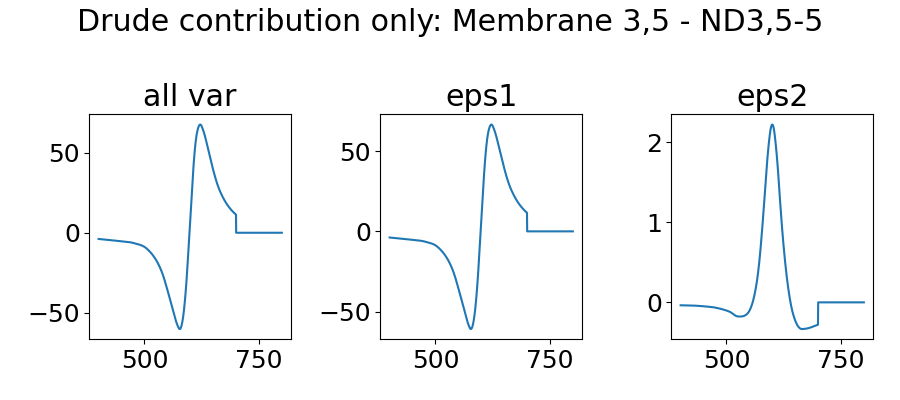

In [ ]:
Lambda = np.linspace(400, 800, 1000)

for key in ND_names :

    plasmon_deriv = Plasmon_derivatives[key]

    fig, ax = plt.subplots(ncols=3, figsize=(9,4))

    fig.suptitle('Drude contribution only: ' + key)

    eps1_var = plasmon_deriv['ds_deps1'](Lambda) * Permittivity_change_interp['a_D'](Lambda)
    eps2_var = plasmon_deriv['ds_deps2'](Lambda) * Permittivity_change_interp['b_D'](Lambda)
    
    
    ax[0].plot(Lambda, eps1_var+eps2_var)
    ax[0].set_title('all var')

    ax[1].plot(Lambda, eps1_var)
    ax[1].set_title('eps1')
    
    ax[2].plot(Lambda, eps2_var)
    ax[2].set_title('eps2')
    plt.tight_layout()

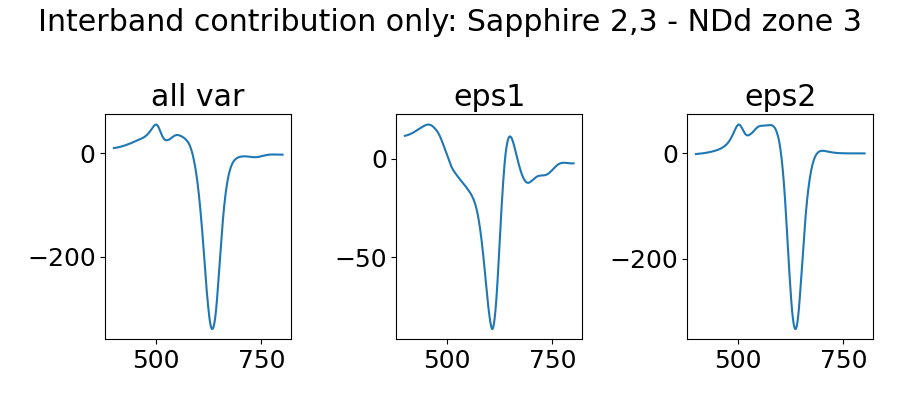

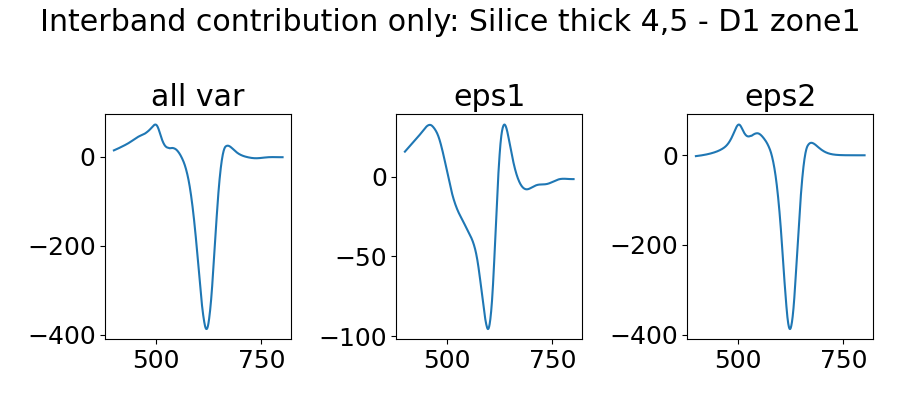

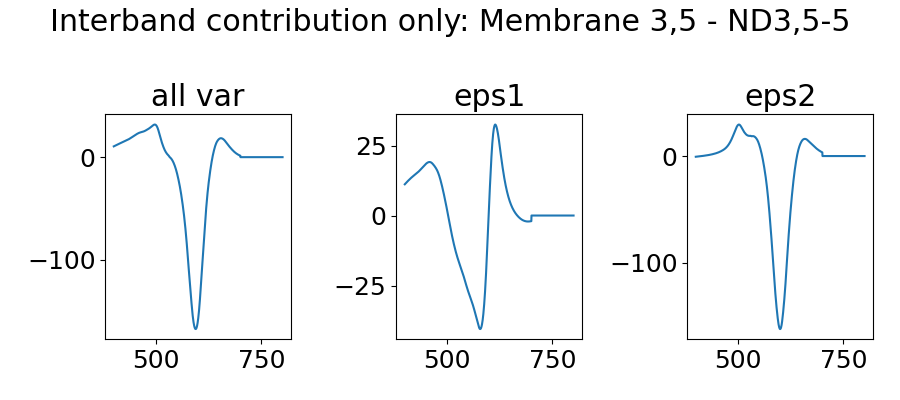

In [ ]:
Lambda = np.linspace(400, 800, 1000)

for key in ND_names :

    plasmon_deriv = Plasmon_derivatives[key]

    fig, ax = plt.subplots(ncols=3, figsize=(9,4))

    fig.suptitle('Interband contribution only: ' + key)

    eps1_var = plasmon_deriv['ds_deps1'](Lambda) * Permittivity_change_interp['a_ib'](Lambda)
    eps2_var = plasmon_deriv['ds_deps2'](Lambda) * Permittivity_change_interp['b_ib'](Lambda)
    
    
    ax[0].plot(Lambda, eps1_var+eps2_var)
    ax[0].set_title('all var')

    ax[1].plot(Lambda, eps1_var)
    ax[1].set_title('eps1')
    
    ax[2].plot(Lambda, eps2_var)
    ax[2].set_title('eps2')
    plt.tight_layout()

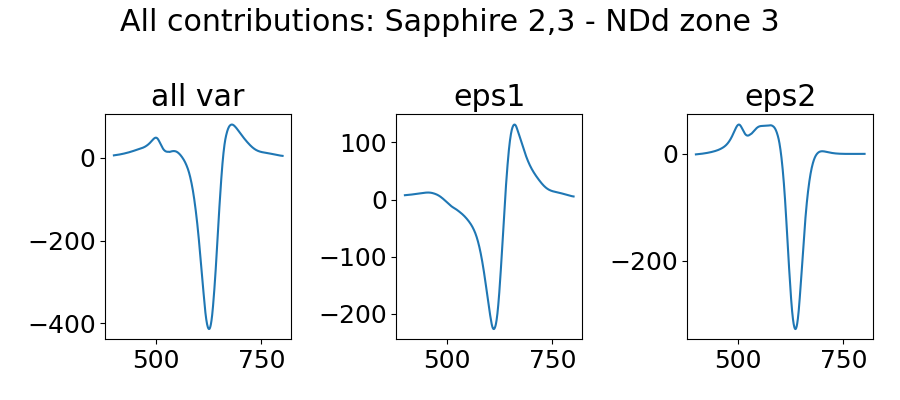

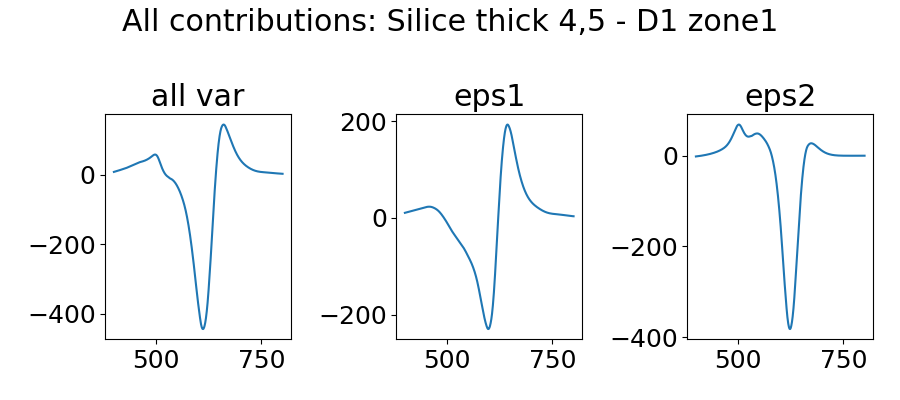

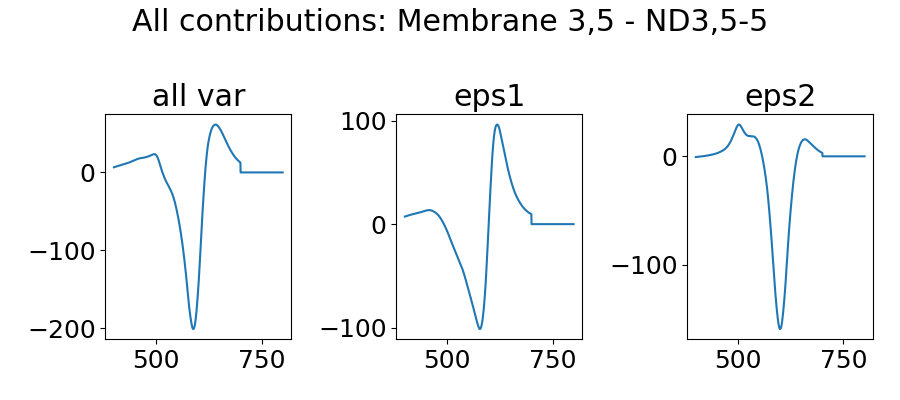

In [ ]:
Lambda = np.linspace(400, 800, 1000)

for key in ND_names :

    plasmon_deriv = Plasmon_derivatives[key]

    fig, ax = plt.subplots(ncols=3, figsize=(9,4))

    fig.suptitle('All contributions: ' + key)
    eps1_var = plasmon_deriv['ds_deps1'](Lambda) * (Permittivity_change_interp['a_D'](Lambda) + Permittivity_change_interp['a_ib'](Lambda))
    eps2_var = plasmon_deriv['ds_deps2'](Lambda) * (Permittivity_change_interp['b_D'](Lambda) + Permittivity_change_interp['b_ib'](Lambda))
    
    
    ax[0].plot(Lambda, eps1_var+eps2_var)
    ax[0].set_title('all var')

    ax[1].plot(Lambda, eps1_var)
    ax[1].set_title('eps1')
    
    ax[2].plot(Lambda, eps2_var)
    ax[2].set_title('eps2')
    plt.tight_layout()